# Text Analysis with Machine Learning in Python
This notebook contains code to utilise a CSV file and to analyse the text contents.

You will need to upload a csv file to this workbook environment to make the code work. In Google Colab you can upload files using the folder icon in the left menu, after connecting to a runtime.

Make sure that your CSV file is clean and tidy - with a row of simple headers at the top.

Make sure that you edit the code below to use your own column names and column numbers from your CSV file.

In [1]:

import pandas as pd

df = pd.read_csv("south_leeds_news_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (10, 4)

Column names: ['Headline', 'URL', 'Date', 'Topic']


,Headline,URL,Date,Topic
0,The Leeds Fund marks ten years of community im...,https://southleedslife.com/the-leeds-fund-mark...,2026-10-26,NaN
1,Middleton’s Falconers Rest closes for refurbis...,https://southleedslife.com/middletons-falconer...,2026-10-26,NaN
2,Celebrating Roald Dahl Day at Cockburn Reach ...,https://southleedslife.com/celebrating-roald-d...,2026-10-25,NaN
3,Boost your confidence at Slung Low workshops,https://southleedslife.com/boost-your-confiden...,2026-10-25,NaN
4,Planning applications 17 October 2026,https://southleedslife.com/planning-applicatio...,2026-10-25,NaN



Missing values:
Headline     0
URL          0
Date         0
Topic       10
dtype: int64


In [2]:

from collections import Counter
import re

# Combine all headlines into one text
text = " ".join(df["Headline"].dropna().astype(str))

# Convert to lowercase and extract words
words = re.findall(r"[a-z]+", text.lower())

# Remove common English words
stopwords = {
    "the", "a", "an", "and", "or", "of", "to",
    "in", "on", "at", "for", "with", "is",
    "are", "was", "were", "by", "from",
    "this", "that", "as", "it", "your"
}

filtered_words = [
    word for word in words
    if word not in stopwords and len(word) > 2
]

# Count word frequency
word_counts = Counter(filtered_words)

# Display the 20 most common words
print("Top 20 most frequent words:")
for word, count in word_counts.most_common(20):
    print(word, ":", count)


Top 20 most frequent words:
reach : 2
october : 2
leeds : 1
fund : 1
marks : 1
ten : 1
years : 1
community : 1
impact : 1
new : 1
cost : 1
living : 1
focus : 1
middleton : 1
falconers : 1
rest : 1
closes : 1
refurbishment : 1
celebrating : 1
roald : 1


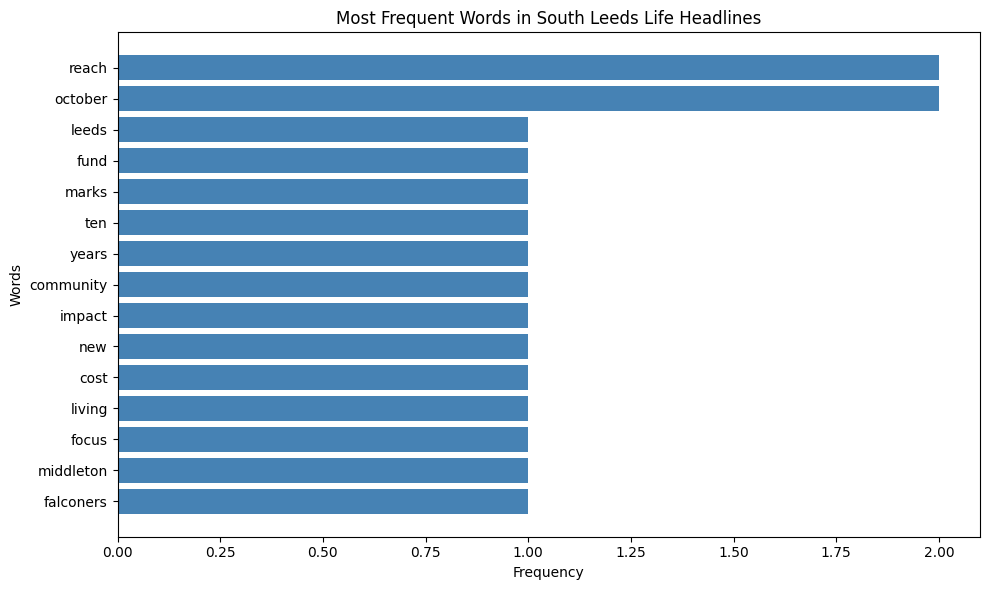

In [3]:

import matplotlib.pyplot as plt

# Select the 15 most frequent words
top_words = word_counts.most_common(15)

words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(words, frequencies, color="steelblue")

plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Most Frequent Words in South Leeds Life Headlines")

# Put the most frequent words at the top
plt.gca().invert_yaxis()

plt.tight_layout()

# Save the chart as an image
plt.savefig("word_frequency_chart.png", dpi=300)

plt.show()


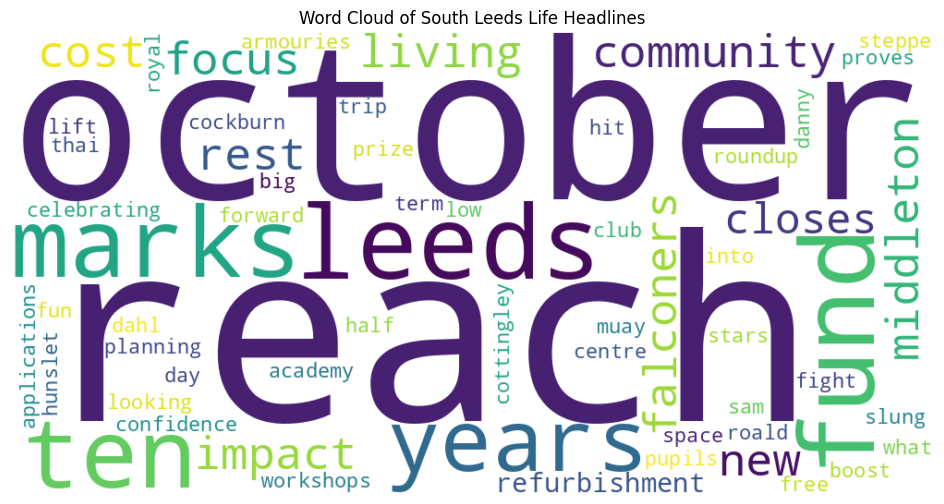

In [4]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Generate a word cloud using the word frequency results
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="viridis",
    random_state=42
).generate_from_frequencies(word_counts)

# Display the word cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of South Leeds Life Headlines")
plt.show()

# Save the result
wordcloud.to_file("south_leeds_wordcloud.png")


In [5]:

import spacy
from collections import Counter

# Load the English NLP model
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    import subprocess
    subprocess.run(
        ["python", "-m", "spacy", "download", "en_core_web_sm"],
        check=True
    )
    nlp = spacy.load("en_core_web_sm")

# Analyse the news headlines
headlines = df["Headline"].dropna().astype(str)

entities = []

for headline in headlines:
    doc = nlp(headline)

    for ent in doc.ents:
        entities.append((ent.text, ent.label_))

# Count identified entities
entity_counts = Counter(entities)

print("Named Entities Found:\n")

for (name, label), count in entity_counts.most_common():
    print(f"{name} | {label} | {count}")


Named Entities Found:

The Leeds Fund | ORG | 1
ten years | DATE | 1
Middleton’s Falconers Rest | ORG | 1
Dahl Day | DATE | 1
Cockburn Reach Academy | ORG | 1
17 | CARDINAL | 1
October 2026 | DATE | 1
Lift Cottingley | PERSON | 1
Space Centre | FAC | 1
the Royal Armouries | FAC | 1
24-30 October 2026 | DATE | 1
Danny | PERSON | 1
Sam | PERSON | 1
Muay Thai | PERSON | 1
The Hunslet Club | ORG | 1


In [6]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# Load the headlines
headlines = df["Headline"].dropna().astype(str)

# Convert the text into numerical features
vectorizer = TfidfVectorizer(
    stop_words="english"
)

X = vectorizer.fit_transform(headlines)

# Group the headlines into 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

# Display the headlines and their clusters
results = pd.DataFrame({
    "Headline": headlines.values,
    "Cluster": clusters
})

display(results.sort_values("Cluster"))


,Headline,Cluster
0,The Leeds Fund marks ten years of community im...,0
1,Middleton’s Falconers Rest closes for refurbis...,0
3,Boost your confidence at Slung Low workshops,0
6,Steppe into free half‑term fun at the Royal Ar...,0
9,Muay Thai proves a big hit at The Hunslet Club,0
8,Danny and Sam looking forward to prize fight,0
2,Celebrating Roald Dahl Day at Cockburn Reach ...,1
5,Lift Cottingley pupils reach for the stars on ...,1
7,What’s On Roundup 24-30 October 2026,2
4,Planning applications 17 October 2026,2


In [7]:

from textblob import TextBlob
import pandas as pd

# Load the news headlines
headlines = df["Headline"].dropna().astype(str)

# Calculate sentiment polarity
sentiment_results = []

for headline in headlines:
    polarity = TextBlob(headline).sentiment.polarity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    sentiment_results.append({
        "Headline": headline,
        "Polarity": round(polarity, 3),
        "Sentiment": sentiment
    })

sentiment_df = pd.DataFrame(sentiment_results)

# Display the results
display(sentiment_df)

# Count sentiment categories
print("\nSentiment distribution:")
print(sentiment_df["Sentiment"].value_counts())


,Headline,Polarity,Sentiment
0,The Leeds Fund marks ten years of community im...,0.068,Positive
1,Middleton’s Falconers Rest closes for refurbis...,0.000,Neutral
2,Celebrating Roald Dahl Day at Cockburn Reach ...,0.000,Neutral
3,Boost your confidence at Slung Low workshops,0.000,Neutral
4,Planning applications 17 October 2026,0.000,Neutral
5,Lift Cottingley pupils reach for the stars on ...,0.000,Neutral
6,Steppe into free half‑term fun at the Royal Ar...,0.350,Positive
7,What’s On Roundup 24-30 October 2026,0.000,Neutral
8,Danny and Sam looking forward to prize fight,0.000,Neutral
9,Muay Thai proves a big hit at The Hunslet Club,0.150,Positive



Sentiment distribution:
Sentiment
Neutral     7
Positive    3
Name: count, dtype: int64


In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Use the South Leeds Life headlines
headlines = df["Headline"].fillna("").astype(str)

# Convert headlines into numerical features
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(headlines)

# Calculate similarity between headlines
similarity_matrix = cosine_similarity(tfidf_matrix)

# Find similar news headlines
def recommend_news(index, n=3):

    scores = list(enumerate(similarity_matrix[index]))

    # Exclude the selected headline itself
    scores = [
        (i, score) for i, score in scores
        if i != index
    ]

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    print("Selected news:")
    print(headlines.iloc[index])

    print("\nMost similar headlines:")

    for i, score in scores[:n]:
        print(f"{headlines.iloc[i]} (similarity={score:.2f})")

# Test with the first headline
recommend_news(0)


Selected news:
The Leeds Fund marks ten years of community impact with new cost of living focus

Most similar headlines:
Middleton’s Falconers Rest closes for refurbishment (similarity=0.00)
Celebrating Roald Dahl Day at  Cockburn Reach Academy (similarity=0.00)
Boost your confidence at Slung Low workshops (similarity=0.00)


In [9]:

# Create a copy of the original news dataset
final_df = df.copy()

# Add sentiment analysis results
final_df["Sentiment_Score"] = sentiment_df["Polarity"].values
final_df["Sentiment_Label"] = sentiment_df["Sentiment"].values

# Add clustering results
final_df["Cluster"] = clusters

# Count named entities in each headline
final_df["Entity_Count"] = [
    len(nlp(str(headline)).ents)
    for headline in final_df["Headline"]
]

# Save the results
final_df.to_csv(
    "South_Leeds_Text_Analysis_Results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Analysis results saved successfully!")
print("Dataset shape:", final_df.shape)

display(final_df.head())


Analysis results saved successfully!
Dataset shape: (10, 8)


,Headline,URL,Date,Topic,Sentiment_Score,Sentiment_Label,Cluster,Entity_Count
0,The Leeds Fund marks ten years of community im...,https://southleedslife.com/the-leeds-fund-mark...,2026-10-26,NaN,0.068,Positive,0,2
1,Middleton’s Falconers Rest closes for refurbis...,https://southleedslife.com/middletons-falconer...,2026-10-26,NaN,0.000,Neutral,0,1
2,Celebrating Roald Dahl Day at Cockburn Reach ...,https://southleedslife.com/celebrating-roald-d...,2026-10-25,NaN,0.000,Neutral,1,2
3,Boost your confidence at Slung Low workshops,https://southleedslife.com/boost-your-confiden...,2026-10-25,NaN,0.000,Neutral,0,0
4,Planning applications 17 October 2026,https://southleedslife.com/planning-applicatio...,2026-10-25,NaN,0.000,Neutral,2,2
